# Walkthrough: an LSTM that writes Mario levels one column at a time

This notebook goes through the pipeline step by step. It assumes you already ran:

```
python scripts/download_data.py
python -m src.train
```

The LSTM only produces a **grid of tile characters**. The pictures are drawn afterwards from that grid. Nothing here is gameplay.

In [1]:
import os, sys
# run from the repository root so that `src` and `config.yaml` are found
if os.path.basename(os.getcwd()) == "notebooks":
    os.chdir("..")
sys.path.insert(0, os.getcwd())

from src.config import load_config
from src.data import load_levels, rows_to_columns, ColumnVocab
cfg = load_config("config.yaml")
legend, levels = load_levels(cfg)
print(len(levels), "levels:", list(levels))
print("legend:", {k: v[1] if len(v) > 1 else v[0] for k, v in legend.items()})

15 levels: ['mario-1-1', 'mario-1-2', 'mario-1-3', 'mario-2-1', 'mario-3-1', 'mario-3-3', 'mario-4-1', 'mario-4-2', 'mario-5-1', 'mario-5-3', 'mario-6-1', 'mario-6-2', 'mario-6-3', 'mario-7-1', 'mario-8-1']
legend: {'X': 'ground', 'S': 'breakable', '-': 'empty', '?': 'question block', 'Q': 'question block', 'E': 'damaging', '<': 'top-left pipe', '>': 'top-right pipe', '[': 'left pipe', ']': 'right pipe', 'o': 'collectable', 'B': 'cannon', 'b': 'cannon'}


## 1. A level is a grid of characters
Here are the first 60 columns of level 1-1. `X` is ground, `?` is a question block, `<>` / `[]` are pipe parts, `E` is an enemy.

In [2]:
for row in levels["mario-1-1"]:
    print(row[:60])

------------------------------------------------------------
------------------------------------------------------------
------------------------------------------------------------
------------------------------------------------------------
------------------------------------------------------------
----------------------Q-------------------------------------
------------------------------------------------------------
------------------------------------------------------------
------------------------------------------------------------
----------------Q---S?SQS---------------------<>---------<>-
--------------------------------------<>------[]---------[]-
----------------------------<>--------[]------[]---------[]-
---------------------E------[]--------[]-E----[]-----E-E-[]-
XXXXXXXXXXXXXXXXXXXXXXXXXXXXXXXXXXXXXXXXXXXXXXXXXXXXXXXXXXXX


## 2. Tokenization: one column = one token
We read the level left to right. Each column of 14 characters is one "word". The vocabulary is the set of distinct columns.

In [3]:
cols = rows_to_columns(levels["mario-1-1"])
print("level 1-1 has", len(cols), "columns, e.g. column 0 top->bottom:", repr(cols[0]))
all_cols = [c for rows in levels.values() for c in rows_to_columns(rows)]
vocab = ColumnVocab(all_cols)
print("distinct columns over all 15 levels:", len(vocab) - 1, "(+1 <unk> token)")
ids = vocab.encode(cols[:10])
print("first 10 ids:", ids)
assert vocab.decode(ids) == cols[:10]   # round trip

level 1-1 has 202 columns, e.g. column 0 top->bottom: '-------------X'
distinct columns over all 15 levels: 271 (+1 <unk> token)
first 10 ids: [2, 2, 2, 2, 2, 2, 2, 2, 2, 2]


## 3. Training samples: 16 columns in, next column out

In [4]:
from src.data import make_windows
X, y = make_windows(vocab.encode(cols), cfg["train"]["window"])
print("windows from level 1-1:", X.shape, "targets:", y.shape)

windows from level 1-1: (186, 16) targets: (186,)


## 4. Load the trained model
The checkpoint contains its own vocabulary, built from the 13 training levels only.

In [5]:
import torch
from src.generate import load_checkpoint
model, tvocab, ckpt = load_checkpoint(cfg["train"]["checkpoint"], torch.device("cpu"))
print("best epoch:", ckpt["epoch"], "| val loss (known targets):", round(ckpt["val_loss"], 3),
      "| val acc:", round(ckpt["val_acc"], 3))
print("train levels:", ckpt["train_levels"])
print("validation levels:", ckpt["val_levels"])

best epoch: 12 | val loss (known targets): 2.446 | val acc: 0.504
train levels: ['mario-1-1', 'mario-1-3', 'mario-2-1', 'mario-3-1', 'mario-3-3', 'mario-4-1', 'mario-4-2', 'mario-5-1', 'mario-5-3', 'mario-6-2', 'mario-6-3', 'mario-7-1', 'mario-8-1']
validation levels: ['mario-1-2', 'mario-6-1']


## 5. What the model predicts for one window
The model outputs one score (logit) per vocabulary column. Dividing by the **temperature** before softmax changes how peaked the distribution is.

In [6]:
from src.data import rows_to_columns
seed_cols = rows_to_columns(levels[ckpt["train_levels"][0]])[:16]
x = torch.tensor([tvocab.encode(seed_cols)])
with torch.no_grad():
    logits = model(x)[0]
logits[tvocab.unk_id] = -float("inf")
for T in (0.5, 1.0, 1.5):
    p = torch.softmax(logits / T, -1)
    top = torch.topk(p, 3)
    print(f"T={T}: top-3 probabilities", [round(v, 3) for v in top.values.tolist()])

T=0.5: top-3 probabilities [0.985, 0.008, 0.003]
T=1.0: top-3 probabilities [0.699, 0.061, 0.037]
T=1.5: top-3 probabilities [0.34, 0.067, 0.048]


## 6. Generate and render a level at three temperatures

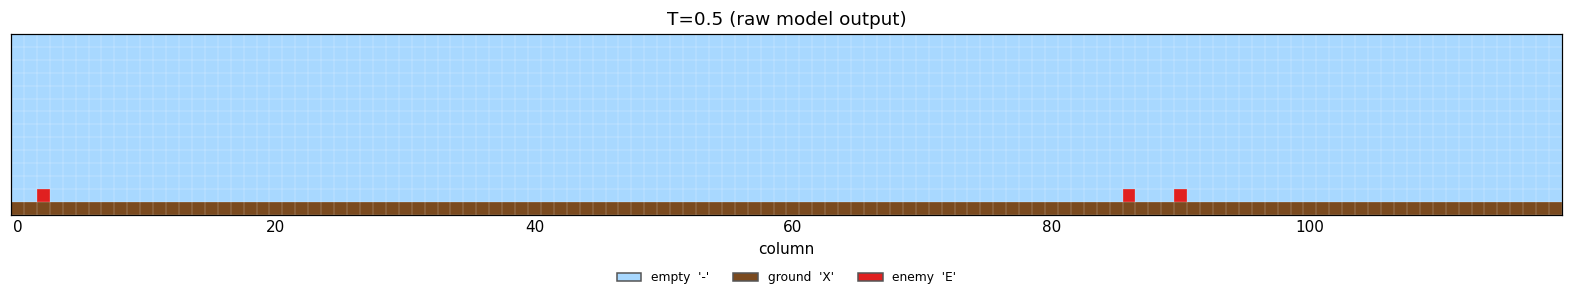

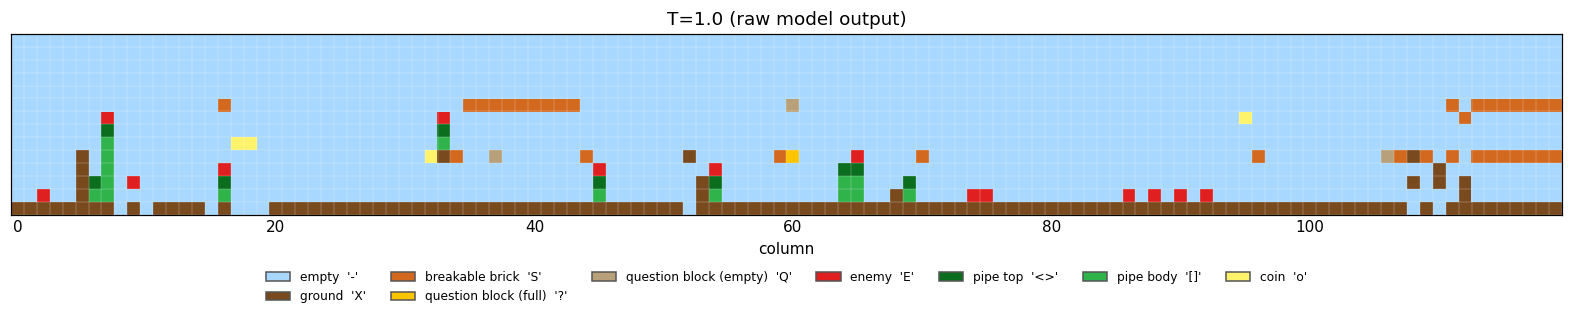

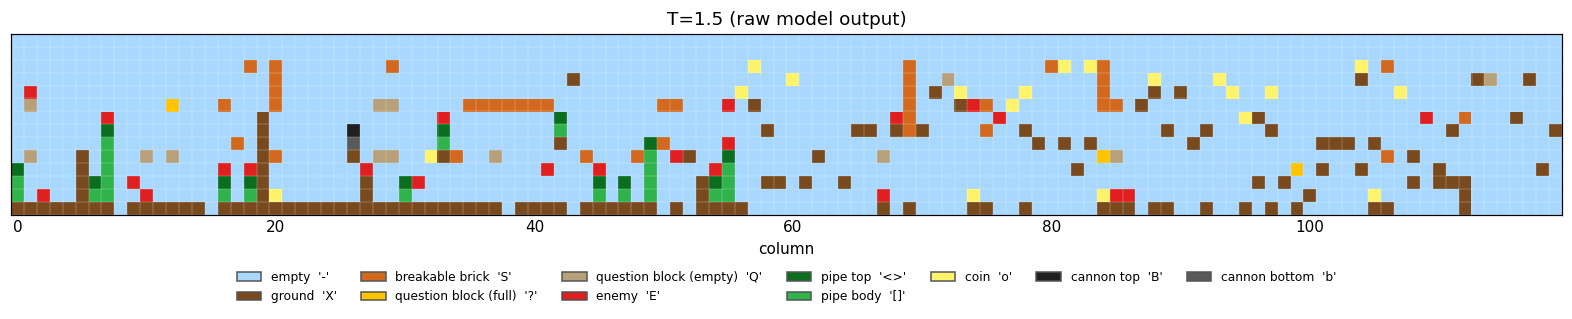

In [7]:
import random
from IPython.display import Image, display
from src.generate import generate_levels
from src.render import save_level_png
os.makedirs("outputs/notebook", exist_ok=True)
for T in (0.5, 1.0, 1.5):
    lv = generate_levels(model, tvocab, levels, ckpt["train_levels"], n=1, length=120,
                         window=16, temperature=T, top_k=0, seed=7)[0]
    path = f"outputs/notebook/T{str(T).replace('.', 'p')}.png"
    save_level_png(lv["rows"], path, f"T={T} (raw model output)")
    display(Image(path))

## 7. Metrics on one generated level vs a real one

In [8]:
from src.evaluate import level_metrics, ngram_set
train_ngrams = set().union(*(ngram_set(levels[n], 8) for n in ckpt["train_levels"]))
print("real 1-1:", level_metrics(levels["mario-1-1"], legend, train_ngrams, 8))
print("generated T=1.5:", level_metrics(lv["rows"], legend, train_ngrams, 8))

real 1-1: {'widest_gap': 3, 'ground_fraction': 0.9653465346534653, 'enemies_per_100': 7.425742574257426, 'qblocks_per_100': 6.435643564356436, 'pipes_valid': 1, 'pipe_errors': 0, 'copy_rate': 1.0, 'width': 202}
generated T=1.5: {'widest_gap': 10, 'ground_fraction': 0.5666666666666667, 'enemies_per_100': 19.166666666666668, 'qblocks_per_100': 13.333333333333334, 'pipes_valid': 0, 'pipe_errors': 34, 'copy_rate': 0.0, 'width': 120}


## What to take away
* Low temperature leads to safe, repetitive output (often long stretches of flat ground) that copies training windows.
* High temperature leads to noise: floating ground, broken pipes, lots of enemies.
* The model knows nothing about jump physics, so none of this says a level is playable.

The full numbers over 50 levels per temperature are produced by `python -m src.evaluate`.